# Notebook 21b — Wu 2003: Reduced-scope control-structure audit for S-B3

## Purpose

This notebook mirrors notebook 21's observational-control audit, but for the reduced-scope
**S-B3** framing. `S-B3` is still the conventional `S-B` instrumentation structure; the change is
the **fault catalogue**, not the controller design. Feed-fault scenarios are removed and `z_A0_eff`
is treated as exogenous, while reactor and column degradation remain in scope.


## Control-structure framing

The original notebook 21 compared `S-A` against `S-B`. In `S-B3`, that head-to-head comparison is
no longer the point. The relevant question is narrower: after removing feed-fault scenarios, does
the retained `S-B` catalogue still exhibit the same physically meaningful signatures that made the
original reactor/column problem interesting?

## Notebook contents

1. Warm-starts and 2-hour windows for all retained `S-B3` closed-loop scenarios
2. F_R_norm trajectories across the retained scenario set
3. Hidden `x_D` trajectories as a diagnostic-only differentiator
4. Steady-state comparison table (end-of-window values under `S-B3`)
5. Open-loop vs closed-loop masking demonstration for retained reactor faults

## Section 1 — Imports and warm starts

The reduced-scope audit should use the strict `S-B3` wrappers so that no free `z_A0_eff` is ever
passed by accident. The raw trajectories remain the original 12-channel Wu2003 outputs, which is
why the tables below still show plant quantities like `Q_j` and `Q_reb` in engineering units.

In [9]:
import sys; sys.path.insert(0, '../src')
import importlib
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cstr_sbi.recycle.scenarios import get_scenario, list_open_loop
import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    list_closed_loop_sb3,
    nominal_warm_start_sb3,
    deterministic_window_sb3,
    fault_unit_sb3_truth,
)

FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']

print('Computing reduced-scope warm start...')
y0_sb3 = nominal_warm_start_sb3()
scenarios = list_closed_loop_sb3()
print(f'S-B3 warm start: z_A={float(y0_sb3[0]):.4f}, T_r={float(y0_sb3[1]):.2f} K')
print(f'Retained scenarios: {len(scenarios)}')

Computing reduced-scope warm start...
S-B3 warm start: z_A=0.5099, T_r=342.26 K
Retained scenarios: 12


## Section 2 — Generate 4-hour windows for all retained scenarios

Each retained reduced-scope scenario is now simulated for a **4-hour** window rather than 2 hours,
so the trajectories have more time to relax toward their controlled operating points. To keep the
same 1-minute historian resolution as notebook 21, the window is saved at **240 time steps**.

The purpose is still the same as the original notebook: generate raw trajectories under the
unchanged `S-B` control structure for every retained `S-B3` scenario before examining which
channels remain informative under the reduced scope.

In [10]:
raw_sb3 = {}
t_h = None
for i, sc in enumerate(scenarios):
    t_s, raw = deterministic_window_sb3(sc, y0=y0_sb3, t_final_h=4.0, n_save=240)
    raw_sb3[sc.name] = np.asarray(raw)
    if t_h is None:
        t_h = np.asarray(t_s)
    print(f'  [{i+1:2d}/{len(scenarios)}] {sc.name}')

print(f'Done. t_h shape={t_h.shape}, raw shape={raw_sb3[scenarios[0].name].shape}')

  [ 1/12] W1_healthy
  [ 2/12] W2_cat_mild
  [ 3/12] W3_cat_severe
  [ 4/12] W4_cat_threshold
  [ 5/12] W5_jacket_mild
  [ 6/12] W6_jacket_severe
  [ 7/12] W7_col_eff_mild
  [ 8/12] W9_reb_fouling
  [ 9/12] W11_reactor_combined
  [10/12] W12_snowball_compound
  [11/12] W15_snowball_threshold
  [12/12] W16_full_multi
Done. t_h shape=(240,), raw shape=(240, 12)


## Section 3 — F_R_norm trajectories: retained scenarios

`F_R_norm` remains the main snowball indicator under the conventional `S-B` structure. This plot
now shows the retained `S-B3` scenarios over a 4-hour window, which should make the steady-state
separation between reactor-driven and column-driven recycle effects easier to inspect than in the
original 2-hour view.

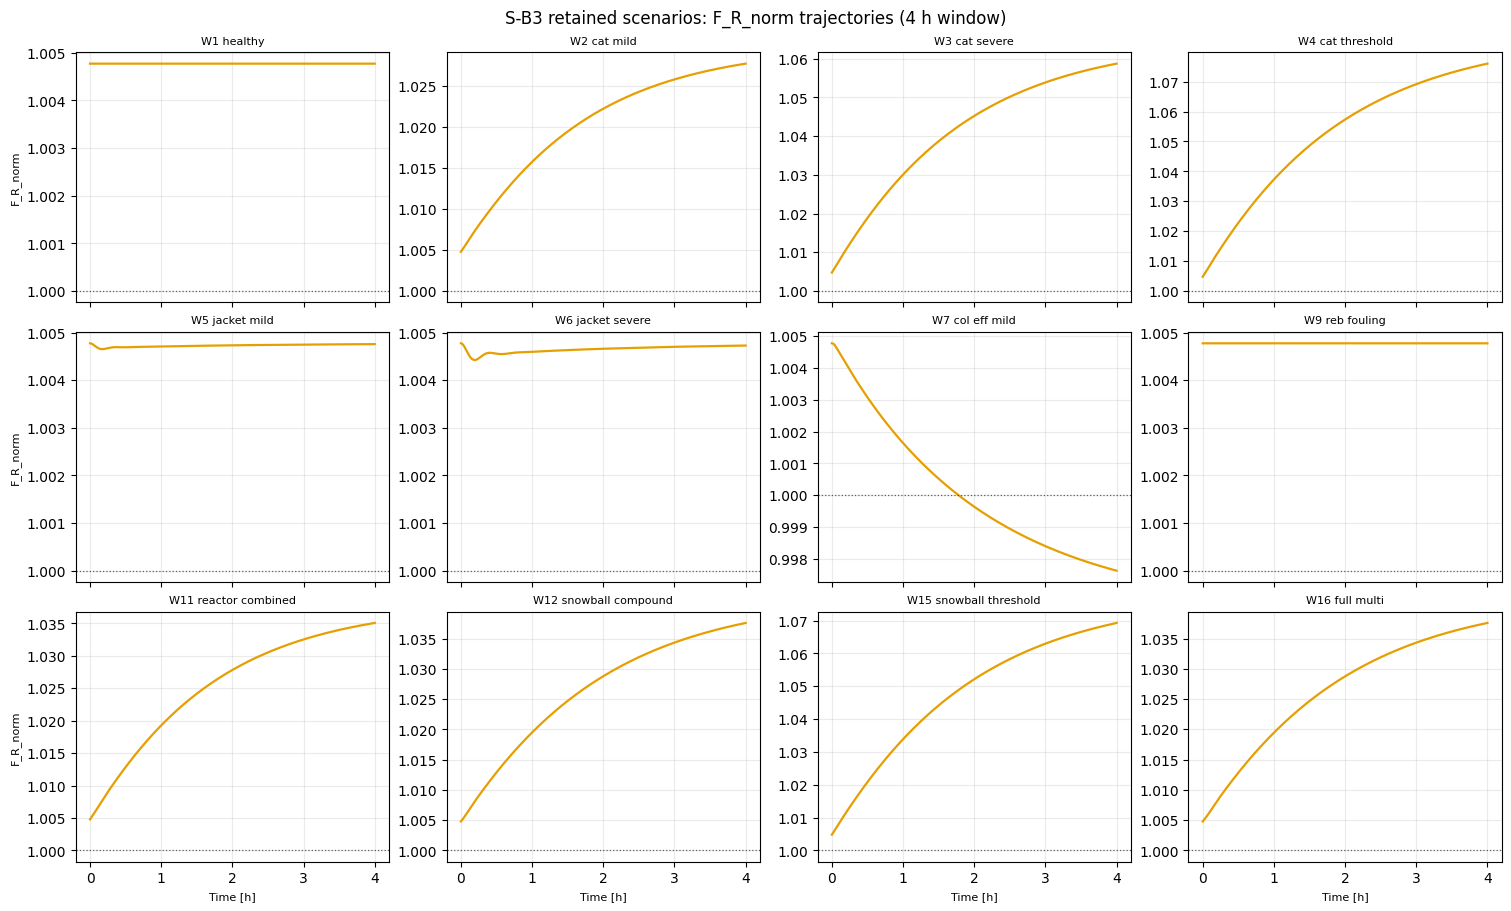

Saved nb21b_fr_norm_all.png


In [11]:
FR_COL = 7
fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True, constrained_layout=True)
axes = axes.flatten()
for i, sc in enumerate(scenarios):
    ax = axes[i]
    ax.plot(t_h, raw_sb3[sc.name][:, FR_COL], color=OI[1], lw=1.6)
    ax.axhline(1.0, color=OI[0], ls=':', lw=0.9, alpha=0.6)
    ax.set_title(sc.name.replace('_', ' '), fontsize=8)
    ax.grid(True, alpha=0.25)
    if i % 4 == 0:
        ax.set_ylabel('F_R_norm', fontsize=8)
    if i >= 8:
        ax.set_xlabel('Time [h]', fontsize=8)
fig.suptitle('S-B3 retained scenarios: F_R_norm trajectories (4 h window)', fontsize=12)
plt.savefig(FIGURES / 'nb21b_fr_norm_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb21b_fr_norm_all.png')

## Section 4 — x_D trajectories: hidden differentiator

`x_D` is still not part of the `S-B` observation set, but plotting it as a hidden diagnostic helps
interpret which retained scenarios are likely to remain ambiguous under `S-B3`. With the longer
4-hour window, the gap between column-driven and reactor-driven hidden composition responses should
be easier to interpret.

### Results commentary: retained F_R_norm and hidden x_D grids

The retained `S-B3` scenario set should preserve the qualitative patterns that mattered in the
original notebook 21:
- reactor snowball cases still raise `F_R_norm`,
- jacket fouling remains largely a masking problem rather than a recycle problem,
- column cases still perturb hidden `x_D` in a way that is diagnostically informative even though
  `S-B` does not observe it directly.

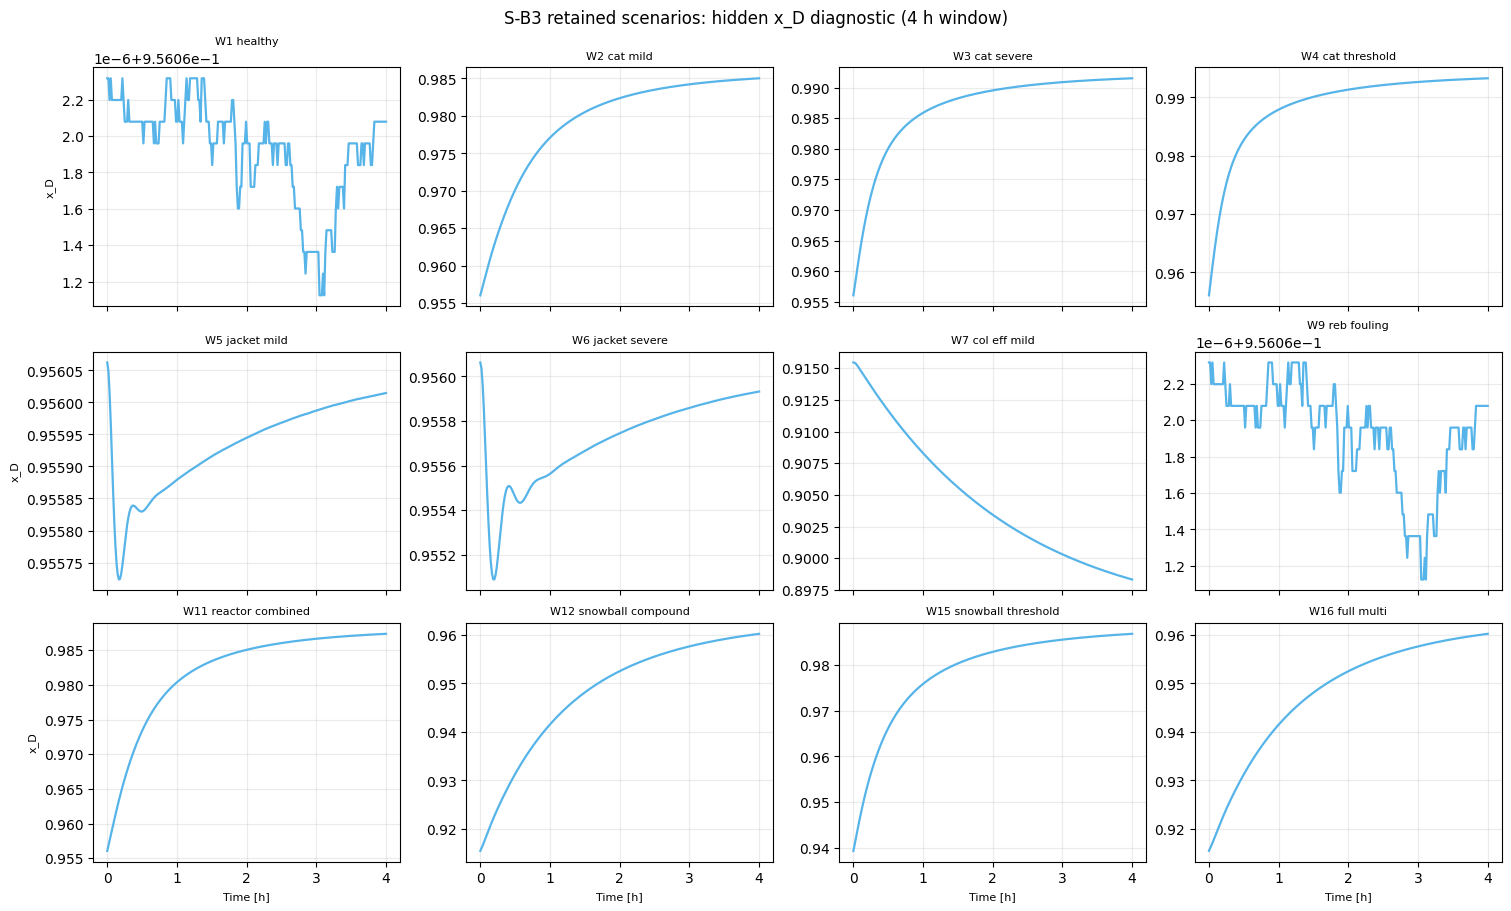

Saved nb21b_xd_all.png


In [12]:
XD_COL = 3
fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True, constrained_layout=True)
axes = axes.flatten()
for i, sc in enumerate(scenarios):
    ax = axes[i]
    ax.plot(t_h, raw_sb3[sc.name][:, XD_COL], color=OI[2], lw=1.6)
    ax.set_title(sc.name.replace('_', ' '), fontsize=8)
    ax.grid(True, alpha=0.25)
    if i % 4 == 0:
        ax.set_ylabel('x_D', fontsize=8)
    if i >= 8:
        ax.set_xlabel('Time [h]', fontsize=8)
fig.suptitle('S-B3 retained scenarios: hidden x_D diagnostic (4 h window)', fontsize=12)
plt.savefig(FIGURES / 'nb21b_xd_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb21b_xd_all.png')

## Section 5 — Steady-state comparison table (`S-B3` end-of-window values)

This table mirrors notebook 21's end-of-window summary, but only for the reduced retained
catalogue. Under the 4-hour window, the end-of-window values are closer to a practical steady-state
readout than they were in the shorter transient-only view.

In [13]:
rows = []
for sc in scenarios:
    raw = raw_sb3[sc.name]
    rows.append({
        'scenario': sc.name,
        'fault_unit_sb3': fault_unit_sb3_truth(np.asarray(sc.theta())[:4]),
        'T_r_final': float(raw[-1, 0]),
        'T_j_final': float(raw[-1, 1]),
        'Q_j_final': float(raw[-1, 2]),
        'x_D_final_hidden': float(raw[-1, 3]),
        'T_reb_final': float(raw[-1, 5]),
        'Q_reb_final': float(raw[-1, 6]),
        'F_R_norm_final': float(raw[-1, 7]),
        'F_B_norm_final': float(raw[-1, 8]),
        'R_norm_final': float(raw[-1, 9]),
        'V_norm_final': float(raw[-1, 10]),
    })
audit_df = pd.DataFrame(rows).sort_values(['fault_unit_sb3', 'scenario']).reset_index(drop=True)
audit_df

group_summary = audit_df.groupby('fault_unit_sb3')[['Q_j_final', 'Q_reb_final', 'F_R_norm_final', 'V_norm_final']].agg(['mean', 'min', 'max'])
group_summary

Q_j_final                        Q_reb_final              \
                        mean        min        max         mean         min   
fault_unit_sb3                                                                
column          9.135174e+06  8938884.0  9331463.0  11695661.25   7372066.5   
healthy         9.331463e+06  9331463.0  9331463.0  11213479.00  11213479.0   
multi           7.319976e+06  7318511.0  7321441.0   9096444.00   8359152.0   
reactor         7.538204e+06  5467914.5  9329754.0   9077968.50   6907872.5   

                           F_R_norm_final                     V_norm_final  \
                       max           mean       min       max         mean   
fault_unit_sb3                                                               
column          16019256.0       1.001201  0.997628  1.004773     0.712985   
healthy         11213479.0       1.004773  1.004773  1.004773     0.910752   
multi            9833736.0       1.037576  1.037570  1.037582     0.500000   
reactor         11216059.0       1.039466  1.004726  1.076004     0.617417   

                                    
                     min       max  
fault_unit_sb3                      
column          0.515217  0.910752  
healthy         0.910752  0.910752  
multi           0.500000  0.500000  
reactor         0.500000  0.911053

## Section 6 — Open-loop vs closed-loop masking (`W5`, `W6`)

The control-masking mechanism is part of the reason the reduced 4-parameter problem remains
interesting. We therefore keep the same masking demonstration, but only for the retained jacket
fouling cases. The 4-hour window makes the contrast between closed-loop regulation and open-loop
drift more visible.

### Results commentary: steady-state table and masking check

The steady-state table should preserve the same qualitative engineering story as notebook 21, but
without any feed-fault rows. The masking check should show that `T_r` is far better regulated under
closed loop than open loop, while `Q_j` moves substantially to compensate jacket fouling.

## Final acceptance criteria

This notebook passes if:
1. all retained `S-B3` scenarios produce finite 4-hour windows,
2. the retained scenario set spans all reduced fault units,
3. the `F_R_norm` and hidden `x_D` grids remain nontrivial across the retained catalogue,
4. the open-loop vs closed-loop masking demonstration still shows meaningful separation for `W5`/`W6`.

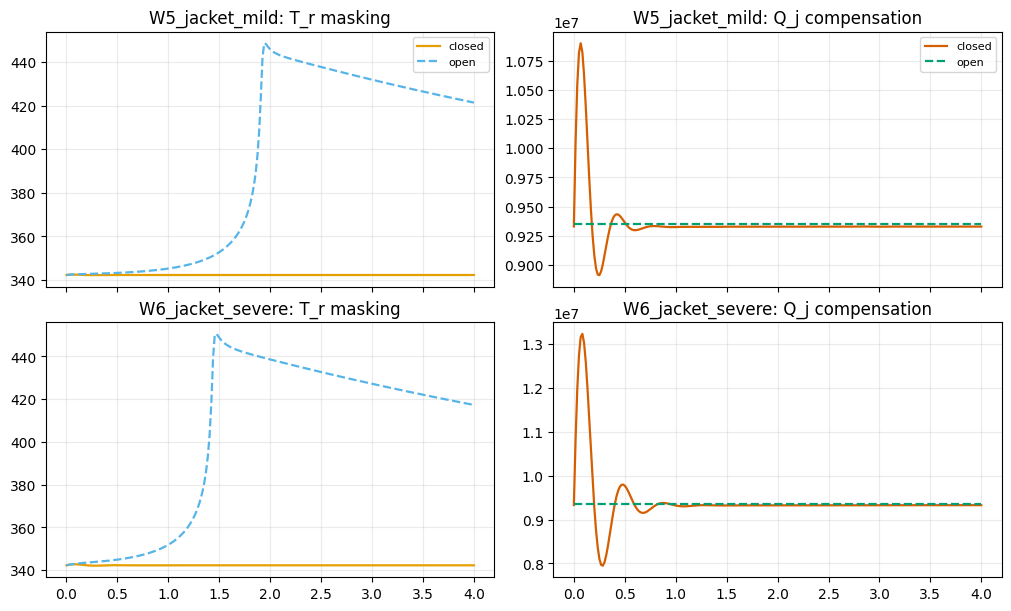

Saved nb21b_masking_open_vs_closed.png
PASS | all retained windows finite: finite check
PASS | all reduced fault units represented: ['column', 'healthy', 'multi', 'reactor']
PASS | F_R_norm varies across retained scenarios: std=0.0274
PASS | hidden x_D varies across retained scenarios: std=0.0264
PASS | masking demonstration separates open vs closed loop: max |T_r(open-closed)|=108.283


In [14]:
open_loop_lookup = {sc.name: sc for sc in list_open_loop()}
mask_cases = [
    ('W5_jacket_mild', 'W5_jacket_mild_ol'),
    ('W6_jacket_severe', 'W6_jacket_severe_ol'),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, constrained_layout=True)
for row_idx, (closed_name, open_name) in enumerate(mask_cases):
    t_closed, raw_closed = deterministic_window_sb3(get_scenario(closed_name), y0=y0_sb3, t_final_h=4.0, n_save=240)
    t_open, raw_open = deterministic_window_sb3(open_loop_lookup[open_name], y0=y0_sb3, t_final_h=4.0, n_save=240)
    raw_closed = np.asarray(raw_closed)
    raw_open = np.asarray(raw_open)
    axes[row_idx, 0].plot(t_closed, raw_closed[:, 0], color=OI[1], lw=1.6, label='closed')
    axes[row_idx, 0].plot(t_open, raw_open[:, 0], color=OI[2], lw=1.6, ls='--', label='open')
    axes[row_idx, 0].set_title(f'{closed_name}: T_r masking')
    axes[row_idx, 0].grid(True, alpha=0.25)
    axes[row_idx, 1].plot(t_closed, raw_closed[:, 2], color=OI[6], lw=1.6, label='closed')
    axes[row_idx, 1].plot(t_open, raw_open[:, 2], color=OI[3], lw=1.6, ls='--', label='open')
    axes[row_idx, 1].set_title(f'{closed_name}: Q_j compensation')
    axes[row_idx, 1].grid(True, alpha=0.25)
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)
plt.savefig(FIGURES / 'nb21b_masking_open_vs_closed.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb21b_masking_open_vs_closed.png')

masking_strength = []
for closed_name, open_name in mask_cases:
    t_closed, raw_closed = deterministic_window_sb3(get_scenario(closed_name), y0=y0_sb3, t_final_h=4.0, n_save=240)
    t_open, raw_open = deterministic_window_sb3(open_loop_lookup[open_name], y0=y0_sb3, t_final_h=4.0, n_save=240)
    raw_closed = np.asarray(raw_closed)
    raw_open = np.asarray(raw_open)
    masking_strength.append(float(np.max(np.abs(raw_open[:, 0] - raw_closed[:, 0]))))
criteria = [
    ('all retained windows finite', bool(all(np.isfinite(raw_sb3[name]).all() for name in raw_sb3)), 'finite check'),
    ('all reduced fault units represented', set(audit_df['fault_unit_sb3']) == {'healthy', 'reactor', 'column', 'multi'}, str(sorted(set(audit_df['fault_unit_sb3'])))),
    ('F_R_norm varies across retained scenarios', float(audit_df['F_R_norm_final'].std()) > 0.0, f"std={audit_df['F_R_norm_final'].std():.4f}"),
    ('hidden x_D varies across retained scenarios', float(audit_df['x_D_final_hidden'].std()) > 0.0, f"std={audit_df['x_D_final_hidden'].std():.4f}"),
    ('masking demonstration separates open vs closed loop', max(masking_strength) > 0.1, f"max |T_r(open-closed)|={max(masking_strength):.3f}"),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

In [15]:
masking_strength = []
for closed_name, open_name in [('W5_jacket_mild', 'W5_jacket_mild_ol'), ('W6_jacket_severe', 'W6_jacket_severe_ol')]:
    t_closed, raw_closed = deterministic_window_sb3(get_scenario(closed_name), y0=y0_sb3)
    t_open, raw_open = deterministic_window_sb3(get_scenario(open_name), y0=y0_sb3)
    raw_closed = np.asarray(raw_closed)
    raw_open = np.asarray(raw_open)
    masking_strength.append(float(np.max(np.abs(raw_open[:, 0] - raw_closed[:, 0]))))
criteria = [
    ('all retained windows finite', bool(all(np.isfinite(raw_sb3[name]).all() for name in raw_sb3)), 'finite check'),
    ('all reduced fault units represented', set(audit_df['fault_unit_sb3']) == {'healthy', 'reactor', 'column', 'multi'}, str(sorted(set(audit_df['fault_unit_sb3'])))),
    ('F_R_norm varies across retained scenarios', float(audit_df['F_R_norm_final'].std()) > 0.0, f"std={audit_df['F_R_norm_final'].std():.4f}"),
    ('hidden x_D varies across retained scenarios', float(audit_df['x_D_final_hidden'].std()) > 0.0, f"std={audit_df['x_D_final_hidden'].std():.4f}"),
    ('masking demonstration separates open vs closed loop', max(masking_strength) > 0.1, f"max |T_r(open-closed)|={max(masking_strength):.3f}"),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

PASS | all retained windows finite: finite check
PASS | all reduced fault units represented: ['column', 'healthy', 'multi', 'reactor']
PASS | F_R_norm varies across retained scenarios: std=0.0274
PASS | hidden x_D varies across retained scenarios: std=0.0264
PASS | masking demonstration separates open vs closed loop: max |T_r(open-closed)|=108.553
